# 04 · EMT-TF Expression — Zhang 2019 Follicular Lymphoma

Unconditional final notebook: score EMT transcription factors on this dataset, gated on detectable
expression, across the Snail/Zeb/Twist families **and** other mesenchymal families (FOXC, PRRX). VIM
(vimentin) is a mesenchymal **marker**, not a TF, and is excluded. Panel cells are shown on the same
scoped Body manifold and house layout used for the trajectory, as a **categorical thresholded overlay**
of expressers on a grey manifold (reference style; not a continuous single-gene colormap). Reads
`processed.h5ad` (raw log-normalized expression), restricted to the Body compartment. Deliverable:
`expression.pdf`.

In [1]:
import os, sys, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load processed expression, restrict to the trajectory Body + apply scoped pseudotime/layout
The trajectory was scoped to the low-cycling Body (02); we carry the same cells, the scoped linear layout
`X_umap_lin`, and pseudotime `t` from `signatures.h5ad` so the EMT overlay is on the same manifold as the
signatures.

In [3]:
proc = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sig  = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))   # Body cells + scoped layout + pseudotime
adata = proc[sig.obs_names].copy()
adata.obsm['X_umap_lin'] = sig.obsm['X_umap_lin']
adata.obs['t'] = sig.obs['t'].values
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('Body cells:', adata.shape[0], '| pseudotime', round(float(t.min()),2), '->', round(float(t.max()),2))

Body cells: 5449 | pseudotime 0.0 -> 9.46


### EMT-TF panel — detection gating + pseudotime polarity
Score a 10-TF candidate panel (Snail/Zeb/Twist + FOXC/PRRX). Report fraction expressing, mean expression
in early vs late pseudotime thirds, and the pseudotime correlation. In this dataset only **ZEB1 and ZEB2**
clear a 3% detection floor; SNAI/TWIST/FOXC/PRRX are essentially undetectable in these malignant B cells.
Both detectable TFs are terminus-loaded (ZEB2 relatively earlier, ZEB1 most terminal) — there is no
root-loaded detectable EMT-TF, so the shown pair spans the observed pseudotime trend rather than an
early-vs-late split.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,_ = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].sort_values('rho_vs_t')
print('\ndetectable TFs (frac>0.03):', ok.TF.tolist())
tf_lo = ok.iloc[0]['TF']; tf_hi = ok.iloc[-1]['TF']
print(f'shown pair (by pseudotime trend): {tf_lo} (relatively earlier) <-> {tf_hi} (most terminal)')

   TF  frac_expr  mean_early  mean_late  rho_vs_t            end
SNAI1      0.003       0.003      0.000    -0.043    EARLY(root)
FOXC1      0.004       0.004      0.003    -0.018    EARLY(root)
SNAI2      0.002       0.001      0.002     0.020 LATE(terminus)
 ZEB2      0.277       0.224      0.289     0.040 LATE(terminus)
 ZEB1      0.117       0.051      0.093     0.092 LATE(terminus)

detectable TFs (frac>0.03): ['ZEB2', 'ZEB1']
shown pair (by pseudotime trend): ZEB2 (relatively earlier) <-> ZEB1 (most terminal)


### EMT-TF overlay — categorical thresholded expressers on a grey manifold (reference style)

overlay thresholds (upper quartile among expressers): {'ZEB2': 1.203, 'ZEB1': 0.777} | cells shown: {'ZEB2': 377, 'ZEB1': 159}
ZEB2: 27.7% expressing; 377 shown (upper quartile), mean pt of shown = 0.55 (all = 0.48)
ZEB1: 11.7% expressing; 159 shown (upper quartile), mean pt of shown = 0.52 (all = 0.48)
saved expression.pdf


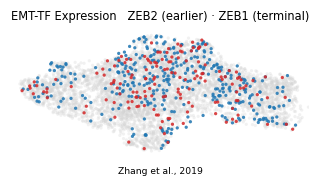

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf_lo, tf_hi]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [tf_lo, tf_hi]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [tf_lo, tf_hi]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [tf_lo, tf_hi]})
order = sorted([tf_lo, tf_hi], key=lambda g: -int(sel[g].sum()))
colors = {tf_lo:'tab:blue', tf_hi:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=18, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=18, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {tf_lo} (earlier) · {tf_hi} (terminal)', size=7.5)
ax.text(.5,-.14,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [tf_lo, tf_hi]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), mean pt of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')